<a href="https://colab.research.google.com/github/hridayrjain/BIS-Lab/blob/main/1BM24CS119_%20Network%20Routing_%20Ant%20Colony%20Optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Hriday R Jain

---

1BM24CS119

Application: Network routing

Problem statement: A computer network consists of routers connected by
communication links with different delays and costs. Develop an ACO-based routing
algorithm to select a path between a source router and a destination router using link
costs and heuristic information.

Objective: Minimize end-to-end communication cost or delay.

ACO best path : A -> B -> C -> D -> E -> F | cost = 10
Dijkstra path : A -> B -> C -> D -> E -> F | cost = 10


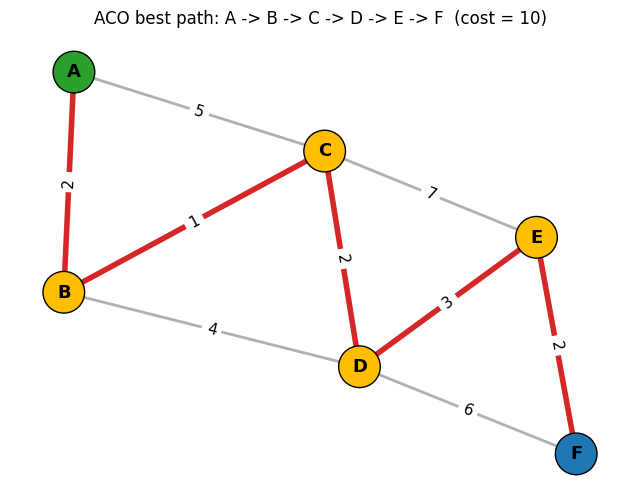

In [5]:
%matplotlib inline
import random, heapq
import matplotlib.pyplot as plt
import networkx as nx


def aco_routing(graph, source, dest, m=10, alpha=1.0, beta=2.0, rho=0.3,
                Q=10.0, tau0=1.0, max_iter=100, patience=20, seed=None):
    if seed is not None:
        random.seed(seed)

    # Initialization: pheromone (tau) and heuristic (eta = 1/cost)
    tau, eta = {}, {}
    for i in graph:
        for j, c in graph[i].items():
            tau[(i, j)] = tau0
            eta[(i, j)] = 1.0 / c

    best_path, best_cost, no_improve = None, float("inf"), 0

    for _ in range(max_iter):
        solutions = []

        # Each ant builds a path from source to destination
        for _ant in range(m):
            current, path, visited = source, [source], {source}
            while current != dest:
                cand = [n for n in graph[current] if n not in visited]
                if not cand:
                    break  # dead end
                w = [(tau[(current, n)] ** alpha) * (eta[(current, n)] ** beta) for n in cand]
                nxt = random.choices(cand, weights=w, k=1)[0]
                path.append(nxt)
                visited.add(nxt)
                current = nxt
            if current == dest:
                cost = sum(graph[path[k]][path[k + 1]] for k in range(len(path) - 1))
                solutions.append((path, cost))

        # Evaporation
        for link in tau:
            tau[link] *= (1 - rho)

        # Pheromone deposit and best-path update
        improved = False
        for path, cost in solutions:
            for k in range(len(path) - 1):
                a, b = path[k], path[k + 1]
                tau[(a, b)] += Q / cost
                tau[(b, a)] += Q / cost
            if cost < best_cost:
                best_cost, best_path, improved = cost, path, True

        no_improve = 0 if improved else no_improve + 1
        if no_improve >= patience:
            break

    return best_path, best_cost


def dijkstra(graph, source, dest):
    """Reference solution to verify the ACO result."""
    dist = {n: float("inf") for n in graph}
    prev, dist[source], pq = {}, 0, [(0, source)]
    while pq:
        d, u = heapq.heappop(pq)
        if d > dist[u]:
            continue
        for v, c in graph[u].items():
            if d + c < dist[v]:
                dist[v] = d + c
                prev[v] = u
                heapq.heappush(pq, (dist[v], v))
    path, node = [dest], dest
    while node != source:
        node = prev[node]
        path.append(node)
    return path[::-1], dist[dest]


def build_graph(edges):
    g = {}
    for u, v, c in edges:
        g.setdefault(u, {})[v] = c
        g.setdefault(v, {})[u] = c
    return g


def draw_network(graph, best_path, cost):
    G = nx.Graph()
    for u in graph:
        for v, c in graph[u].items():
            G.add_edge(u, v, weight=c)

    pos = nx.spring_layout(G, seed=7)
    path_edges = list(zip(best_path, best_path[1:]))
    other = [e for e in G.edges() if e not in path_edges and e[::-1] not in path_edges]

    plt.figure(figsize=(8, 6))
    nx.draw_networkx_edges(G, pos, edgelist=other, edge_color="#b0b0b0", width=2)
    nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color="#d62728", width=4)
    colors = ["#2ca02c" if n == best_path[0] else "#1f77b4" if n == best_path[-1]
              else "#ffbf00" if n in best_path else "#dddddd" for n in G.nodes()]
    nx.draw_networkx_nodes(G, pos, node_color=colors, node_size=900, edgecolors="black")
    nx.draw_networkx_labels(G, pos, font_size=13, font_weight="bold")
    nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"), font_size=11)
    plt.title("ACO best path: " + " -> ".join(best_path) + f"  (cost = {cost})")
    plt.axis("off")
    plt.show()   # the only place the graph is displayed


# ---------- Run ----------
edges = [("A", "B", 2), ("A", "C", 5), ("B", "C", 1), ("B", "D", 4), ("C", "D", 2),
         ("C", "E", 7), ("D", "E", 3), ("D", "F", 6), ("E", "F", 2)]
network = build_graph(edges)
src, dst = "A", "F"

path, cost = aco_routing(network, src, dst, m=10, alpha=1, beta=2,
                         rho=0.3, Q=10, max_iter=100, seed=42)
print("ACO best path :", " -> ".join(path), "| cost =", cost)

opt_path, opt_cost = dijkstra(network, src, dst)
print("Dijkstra path :", " -> ".join(opt_path), "| cost =", opt_cost)

draw_network(network, path, cost)